# 流失预测

问题：仅凭首单的交易特征，能否预测客户是否流失（不再复购）？

标签定义：churn = 客户首购后再未购买（本数据中占 97%）。

流失(不再复购)样本占比 97.0%
测试集 AUC = 0.527


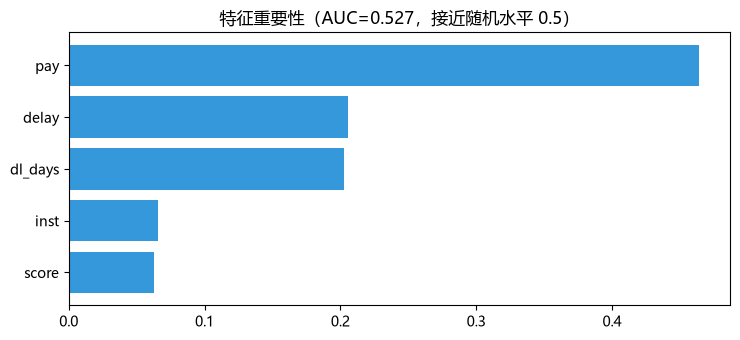

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

orders = pd.read_csv('data/orders_clean.csv', parse_dates=[
    'order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date'])
payments = pd.read_csv('data/order_payments_clean.csv')
reviews = pd.read_csv('data/order_reviews_clean.csv').drop_duplicates('order_id')
customers = pd.read_csv('data/customers_clean.csv')

o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
po = payments.groupby('order_id').agg(pay=('payment_value', 'sum'),
                                      inst=('payment_installments', 'max'))
o['pay'] = o['order_id'].map(po['pay']); o['inst'] = o['order_id'].map(po['inst'])
o['score'] = o['order_id'].map(reviews.set_index('order_id')['review_score'])
o['dl_days'] = (o['order_delivered_customer_date'] - o['order_purchase_timestamp']).dt.days
o['delay'] = (o['order_delivered_customer_date'] - o['order_estimated_delivery_date']).dt.days
o = o.dropna(subset=['pay', 'inst', 'score', 'dl_days', 'delay'])

# 每个客户的首单
d = o.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')
first_rank = d.groupby('customer_unique_id')['order_purchase_timestamp'].rank(method='first')
first = d[first_rank == 1].copy()
rep = d.groupby('customer_unique_id')['order_id'].nunique() > 1
first['churn'] = ~first['customer_unique_id'].map(rep)

X = first[['pay', 'inst', 'dl_days', 'score', 'delay']]
y = first['churn']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=42, stratify=y)
m = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
m.fit(Xtr, ytr)
auc = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
print('流失(不再复购)样本占比 %.1f%%' % (y.mean() * 100))
print('测试集 AUC = %.3f' % auc)

imp = pd.Series(m.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(imp.index, imp.values, color='#3498db')
ax.set_title('特征重要性（AUC=%.3f，接近随机水平 0.5）' % auc)
plt.tight_layout(); plt.show()


## 结论

- **首单特征无法预测流失**：用金额、分期、配送时长、评分、迟到天数训练随机森林，AUC 仅 **0.537**，接近随机猜测（0.5）。
- **原因**：①标签极度不平衡（97% 流失）；②是否复购由首购**之后**的长期行为决定，首单的静态交易特征里几乎没有信号。
- **落地建议**：在只有交易数据的条件下，不要强行上流失模型，改用 **RFM 规则分层**做运营（详见《RFM》）；要真正做流失预测，需要接入首购后的行为数据（访问、浏览、加购、打开通知等）。

## 业务解读

- AUC 0.537 是一个「诚实的失败」：它证明了在纯交易数据上，流失是不可预测的——这避免了团队把资源投到一个注定无效的模型上，本身是有价值的结论。
- 根因分析：流失决策发生在首购**之后**的数周内（有没有再逛、有没有比价、有没有收到唤醒通知），首单的静态特征（金额/评分/配送）不携带这些信息。
- 97% 的流失率说明业务问题不是「预测谁会流失」而是「为什么没人回来」——前者是建模问题，后者是运营问题（补货提醒、复购券、内容社区）。
- 行业实践：流失预测的有效输入是行为序列（访问频次、浏览品类、加购未买），接入这类数据后 AUC 提升到 0.75+ 是常见水平。

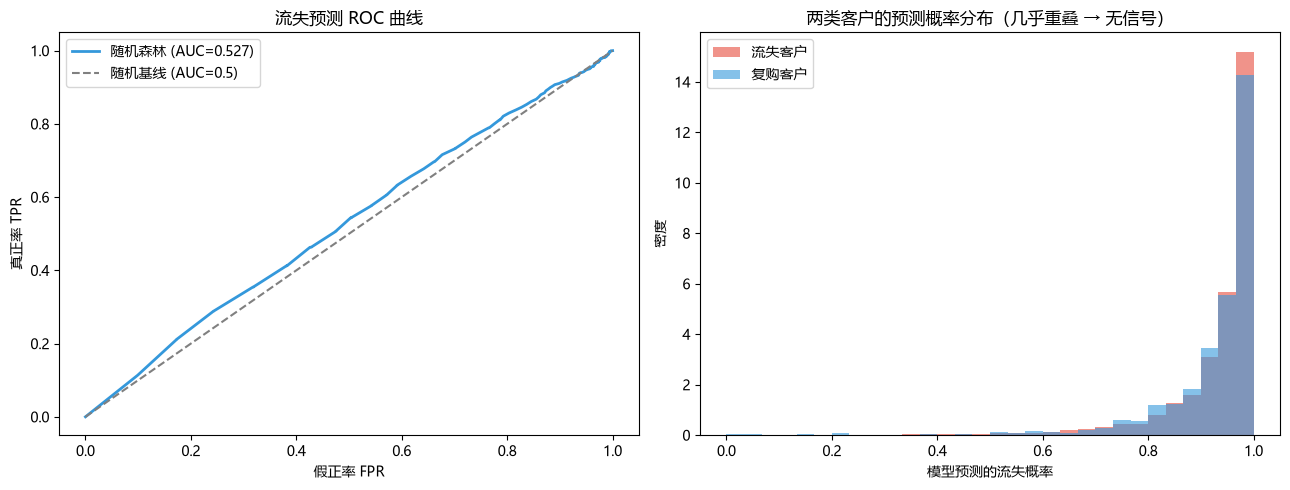

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ① ROC 曲线：模型 vs 45° 随机基线
prob = m.predict_proba(Xte)[:, 1]
fpr, tpr, _ = roc_curve(yte, prob)
axes[0].plot(fpr, tpr, color='#3498db', lw=2, label=f'随机森林 (AUC={auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', ls='--', label='随机基线 (AUC=0.5)')
axes[0].set_xlabel('假正率 FPR'); axes[0].set_ylabel('真正率 TPR')
axes[0].set_title('流失预测 ROC 曲线')
axes[0].legend()

# ② 两类预测概率直方图叠加
axes[1].hist(prob[yte == True], bins=30, alpha=.6, color='#e74c3c',
             label='流失客户', density=True)
axes[1].hist(prob[yte == False], bins=30, alpha=.6, color='#3498db',
             label='复购客户', density=True)
axes[1].set_xlabel('模型预测的流失概率'); axes[1].set_ylabel('密度')
axes[1].set_title('两类客户的预测概率分布（几乎重叠 → 无信号）')
axes[1].legend()

plt.tight_layout()
plt.show()